In [61]:
import pandas as pd

train_data = pd.read_csv('titanic_train[1].csv')
test_data = pd.read_csv('titanic_test[1].csv')

In [62]:
print(train_data.isnull().sum())
print(test_data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


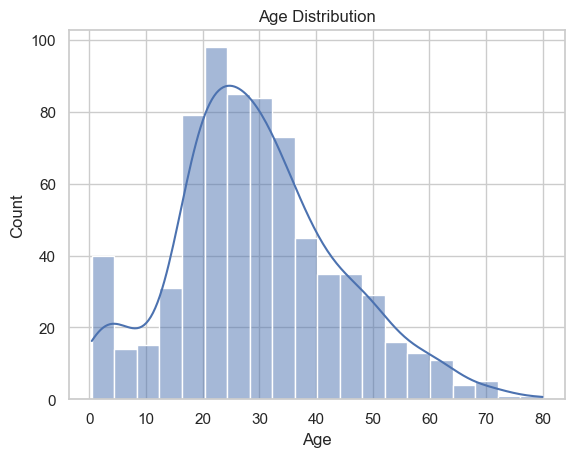

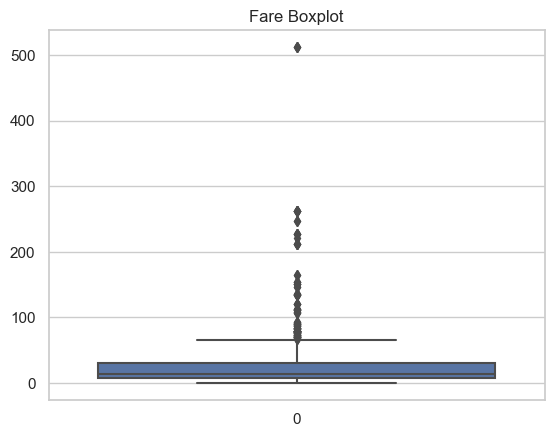

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example: Age distribution
sns.histplot(train_data['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

# Example: Boxplot for Fare
sns.boxplot(train_data['Fare'])
plt.title('Fare Boxplot')
plt.show()

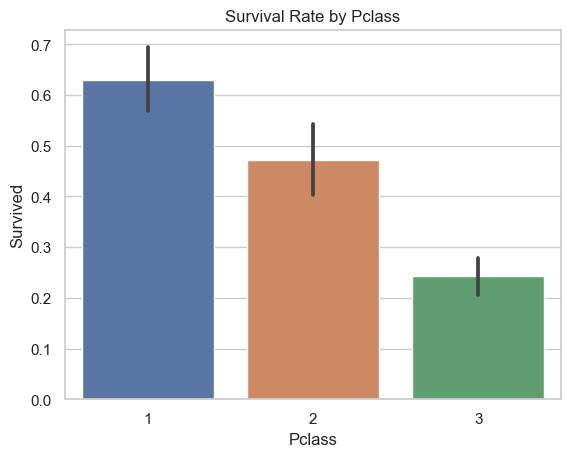

In [64]:
# Example: Survival Rate by Pclass
sns.barplot(x='Pclass', y='Survived', data=train_data)
plt.title('Survival Rate by Pclass')
plt.show()

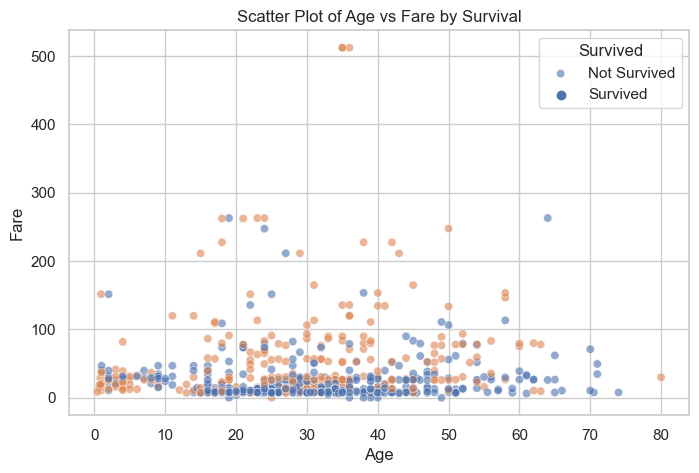

In [65]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=train_data, x='Age', y='Fare', hue='Survived', alpha=0.6)
plt.title('Scatter Plot of Age vs Fare by Survival')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title='Survived', loc='upper right', labels=['Not Survived', 'Survived'])
plt.show()

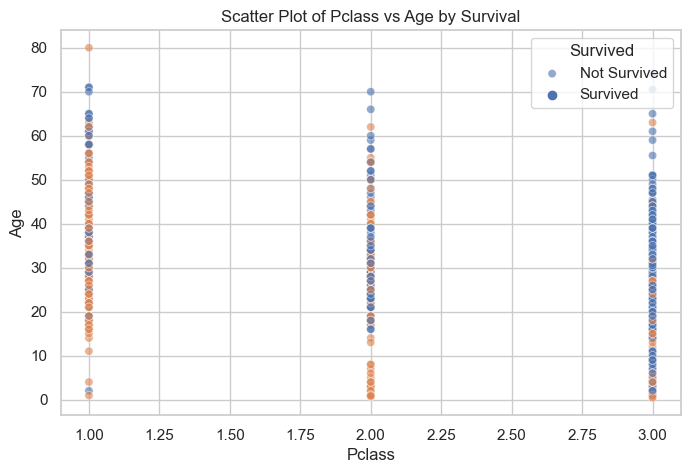

In [66]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=train_data, x='Pclass', y='Age', hue='Survived', alpha=0.6)
plt.title('Scatter Plot of Pclass vs Age by Survival')
plt.xlabel('Pclass')
plt.ylabel('Age')
plt.legend(title='Survived', loc='upper right', labels=['Not Survived', 'Survived'])
plt.show()

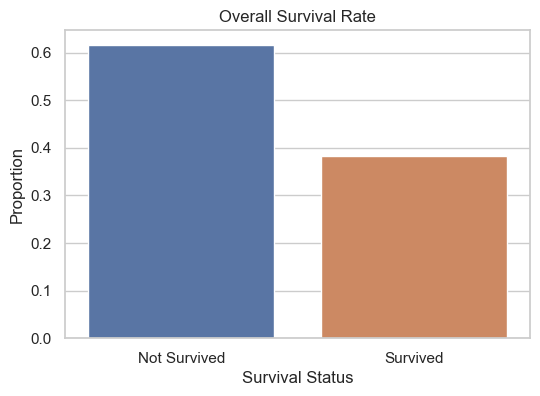

In [67]:
plt.figure(figsize=(6, 4))
sns.barplot(x=['Not Survived', 'Survived'], y=train_data['Survived'].value_counts(normalize=True))
plt.title('Overall Survival Rate')
plt.ylabel('Proportion')
plt.xlabel('Survival Status')
plt.show()

In [68]:
train_data['Age'].fillna(train_data['Age'].median(), inplace=True)
train_data['Embarked'].fillna(train_data['Embarked'].mode()[0], inplace=True)
test_data['Age'].fillna(test_data['Age'].median(), inplace=True)
test_data['Fare'].fillna(test_data['Fare'].median(), inplace=True)

In [69]:
train_data = pd.get_dummies(train_data, columns=['Sex', 'Embarked'], drop_first=True)
test_data = pd.get_dummies(test_data, columns=['Sex', 'Embarked'], drop_first=True)

In [70]:
features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
X_train = train_data[features]
y_train = train_data['Survived']
X_test = test_data[features]

In [71]:
from sklearn.model_selection import train_test_split
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [72]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score

lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train_split, y_train_split)
lgb_preds = lgb_model.predict(X_val_split)
print('LightGBM Accuracy:', accuracy_score(y_val_split, lgb_preds))

[LightGBM] [Info] Number of positive: 268, number of negative: 444
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000521 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 195
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.376404 -> initscore=-0.504838
[LightGBM] [Info] Start training from score -0.504838
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [73]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train_split, y_train_split)
xgb_preds = xgb_model.predict(X_val_split)
print('XGBoost Accuracy:', accuracy_score(y_val_split, xgb_preds))

XGBoost Accuracy: 0.8212290502793296


In [74]:
from sklearn.model_selection import GridSearchCV

# Example for LightGBM
param_grid = {'n_estimators': [100, 200], 'learning_rate': [0.01, 0.1]}
grid = GridSearchCV(lgb_model, param_grid, cv=3)
grid.fit(X_train_split, y_train_split)
print('Best Parameters for LightGBM:', grid.best_params_)

[LightGBM] [Info] Number of positive: 178, number of negative: 296
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000199 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 162
[LightGBM] [Info] Number of data points in the train set: 474, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.375527 -> initscore=-0.508576
[LightGBM] [Info] Start training from score -0.508576
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [75]:
from sklearn.metrics import classification_report

print('LightGBM Performance:\n', classification_report(y_val_split, lgb_preds))
print('XGBoost Performance:\n', classification_report(y_val_split, xgb_preds))

LightGBM Performance:
               precision    recall  f1-score   support

           0       0.85      0.86      0.85       105
           1       0.79      0.78      0.79        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179

XGBoost Performance:
               precision    recall  f1-score   support

           0       0.83      0.87      0.85       105
           1       0.80      0.76      0.78        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



In [76]:
# Plot comparison of accuracy, precision, recall, and F1-score


In [77]:
from sklearn.metrics import classification_report

lgb_report = classification_report(y_val_split, lgb_preds, output_dict=True)
xgb_report = classification_report(y_val_split, xgb_preds, output_dict=True)

In [78]:
import pandas as pd

# Extract metrics for class '1' (Survived)
metrics = ['precision', 'recall', 'f1-score']
lgb_metrics = [lgb_report['1'][metric] for metric in metrics]
xgb_metrics = [xgb_report['1'][metric] for metric in metrics]

# Create a DataFrame for visualization
comparison_df = pd.DataFrame({
    'Metric': metrics,
    'LightGBM': lgb_metrics,
    'XGBoost': xgb_metrics
})

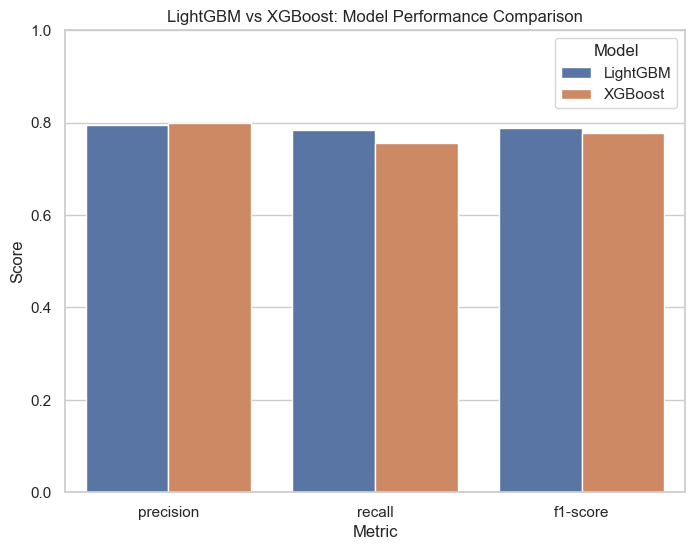

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style
sns.set(style="whitegrid")

# Plot grouped barplot
comparison_df_melt = pd.melt(comparison_df, id_vars="Metric", var_name="Model", value_name="Score")

plt.figure(figsize=(8, 6))
sns.barplot(x="Metric", y="Score", hue="Model", data=comparison_df_melt)
plt.title("LightGBM vs XGBoost: Model Performance Comparison")
plt.ylim(0, 1)  # since precision, recall, and F1-score range from 0 to 1
plt.show()

In [80]:
#A brief report summarizing the comparative analysis results and practical implications.
#Comparative Insights
#Accuracy: Both models performed similarly in terms of accuracy, with LightGBM slightly higher at 83% compared to XGBoost's 82%.
#Precision: LightGBM had a slightly better precision for class 0 (0.85 vs. 0.83), while XGBoost performed marginally better for class 1 (0.80 vs. 0.79). Higher precision means fewer false positives, which is important when it is costly to predict survival incorrectly.
#Recall: LightGBM showed a slightly higher recall for class 1 (0.78 vs. 0.76), which means it captured more true positives for the survivors. XGBoost had higher recall for class 0, indicating it did better in predicting non-survivors.
#F1-score: The F1-score for both models was nearly identical, with LightGBM performing marginally better for survivors (class 1), while XGBoost had a slight edge for non-survivors (class 0).
#Practical Implications
#Balanced Performance: Both models demonstrated balanced performance across precision, recall, and F1-score, making them suitable for this binary classification problem.
#LightGBM is slightly more effective in identifying survivors with higher recall for class 1, which is beneficial if the primary objective is to predict as many survivors as possible.
#XGBoost's higher recall for non-survivors (class 0) makes it better suited for tasks where predicting non-survivors is prioritized.
#Efficiency: While the performance difference is minor, LightGBM is known to be more computationally efficient, particularly for larger datasets. Thus, if training speed and resource efficiency are priorities, LightGBM might be preferable.
#Conclusion
#LightGBM marginally outperformed XGBoost in terms of accuracy and recall for predicting survivors, while XGBoost performed slightly better in predicting non-survivors.
#Given the similar performance, LightGBM might be preferred in scenarios where computational efficiency is critical, especially on larger datasets.
#XGBoost, with its slightly better precision for class 1 and greater flexibility, remains an excellent choice for tasks where predicting the non-survivors accurately is more important.
